In [17]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

raw_dir = Path("../data/raw")

files = {
    "salaries": "american_soccer_analysis_mls_salaries_players.csv",
    "goals_added_gk": "american_soccer_analysis_mls_goals-added_goalkeepers.csv",
    "goals_added": "american_soccer_analysis_mls_goals-added_players.csv",
    "xgoals": "american_soccer_analysis_mls_xgoals_players.csv",
    "xpass": "american_soccer_analysis_mls_xpass_players.csv",
}

salaries = pd.read_csv(raw_dir / files["salaries"])

print(f"Rows: {len(salaries):,}")

display(salaries.head(10))

display(
    salaries.dtypes.rename("dtype").to_frame()
)

Rows: 15,490


,Unnamed: 0,Player,Team,Season,Position,Base Salary,Guaranteed Compensation,Date
0,NaN,Lionel Messi,MIA,2026,F,"$25,000,000","$28,333,332",2026-04-16
1,NaN,Lionel Messi,MIA,2023,M,"$12,000,000","$20,446,668",2023-09-15
2,NaN,Lionel Messi,MIA,2024,F,"$12,000,000","$20,446,668",2024-04-25
3,NaN,Lionel Messi,MIA,2024,F,"$12,000,000","$20,446,668",2024-09-13
4,NaN,Lionel Messi,MIA,2025,F,"$12,000,000","$20,446,668",2025-05-23
5,NaN,Lionel Messi,MIA,2025,F,"$12,000,000","$20,446,668",2025-10-01
6,NaN,Lorenzo Insigne,TOR,2023,M,"$7,500,000","$15,400,000",2023-09-15
7,NaN,Lorenzo Insigne,TOR,2024,F,"$7,500,000","$15,400,000",2024-04-25
8,NaN,Lorenzo Insigne,TOR,2024,F,"$7,500,000","$15,400,000",2024-09-13
9,NaN,Lorenzo Insigne,TOR,2025,F,"$7,500,000","$15,400,000",2025-05-23


,dtype
Unnamed: 0,float64
Player,str
Team,str
Season,int64
Position,str
Base Salary,str
Guaranteed Compensation,str
Date,str


In [3]:
salary_eda = salaries.copy()

salary_eda["Date"] = pd.to_datetime(salary_eda["Date"])

salary_cols = ["Base Salary", "Guaranteed Compensation"]

for col in salary_cols:
    salary_eda[col] = pd.to_numeric(
        salary_eda[col].str.replace(r"[$,]", "", regex=True)
    )

report_schedule = (
    salary_eda
    .groupby(["Season", "Date"])
    .agg(
        records=("Player", "size"),
        unique_names=("Player", "nunique")
    )
    .reset_index()
    .sort_values(["Season", "Date"])
)

display(report_schedule)

,Season,Date,records,unique_names
0,2016,2016-05-15,548,548
1,2016,2016-09-15,580,580
2,2017,2017-04-15,614,614
3,2017,2017-09-15,653,653
4,2018,2018-05-01,661,661
5,2018,2018-09-15,684,684
6,2019,2019-06-01,681,681
7,2019,2019-09-13,705,705
8,2020,2020-12-01,771,771
9,2021,2021-04-15,781,781


In [6]:
report_frequency = (
    salary_eda
    .groupby(["Player", "Season"])["Date"]
    .nunique()
    .value_counts()
    .sort_index()
    .rename_axis("report_count")
    .reset_index(name="player_seasons")
)

display(report_frequency)

,report_count,player_seasons
0,1,2729
1,2,6378


In [7]:
duplicate_records = salary_eda[
    salary_eda.duplicated(
        subset=["Player", "Season", "Date"],
        keep=False
    )
].sort_values(["Player", "Season", "Date"])

display(duplicate_records)

,Unnamed: 0,Player,Team,Season,Position,Base Salary,Guaranteed Compensation,Date
12835,NaN,Anthony Ramirez,FCD,2025,F,80622,80622,2025-05-23
12971,NaN,Anthony Ramirez,FCD,2025,F,80622,80622,2025-05-23
12836,NaN,Anthony Ramirez,FCD,2025,F,80622,80622,2025-10-01
12972,NaN,Anthony Ramirez,FCD,2025,F,80622,80622,2025-10-01
4266,NaN,David Martínez,LAFC,2024,F,500000,500000,2024-09-13
6497,NaN,David Martínez,MIA,2024,D,150000,289839,2024-09-13
2037,NaN,David Martínez,MIA,2025,D,700000,839839,2025-05-23
4031,NaN,David Martínez,LAFC,2025,F,525000,525000,2025-05-23
4030,NaN,David Martínez,LAFC,2025,F,525000,525000,2025-10-01
4032,NaN,David Martínez,LAFC,2025,F,525000,525000,2025-10-01


In [8]:
salary_comparison = salary_eda.drop_duplicates().copy()

ambiguous = salary_comparison.duplicated(
    subset=["Player", "Season", "Date"],
    keep=False
)

ambiguous_keys = (
    salary_comparison.loc[ambiguous, ["Player", "Season"]]
    .drop_duplicates()
)

salary_comparison = salary_comparison.merge(
    ambiguous_keys.assign(ambiguous=True),
    on=["Player", "Season"],
    how="left"
)

salary_comparison = salary_comparison[
    salary_comparison["ambiguous"].isna()
].drop(columns=["ambiguous"])

keys = ["Player", "Season"]

paired = (
    salary_comparison
    .sort_values("Date")
    .groupby(keys)
    .filter(lambda group: group["Date"].nunique() == 2)
)

grouped = paired.groupby(keys)

first = grouped.first()
last = grouped.last()

changes = pd.DataFrame({
    "first_date": first["Date"],
    "last_date": last["Date"],
    "first_team": first["Team"],
    "last_team": last["Team"],
    "base_first": first["Base Salary"],
    "base_last": last["Base Salary"],
    "gc_first": first["Guaranteed Compensation"],
    "gc_last": last["Guaranteed Compensation"]
}).reset_index()

changes["base_change"] = (
    changes["base_last"] - changes["base_first"]
)

changes["gc_change"] = (
    changes["gc_last"] - changes["gc_first"]
)

display(changes.head())
print(f"Comparable player-seasons: {len(changes):,}")

,Player,Season,first_date,last_date,first_team,last_team,base_first,base_last,gc_first,gc_last,base_change,gc_change
0,A.J. DeLaGarza,2016,2016-05-15,2016-09-15,LAG,LAG,225000,225000,227500,227500,0,0
1,A.J. DeLaGarza,2017,2017-04-15,2017-09-15,HOU,HOU,250000,250000,252500,252500,0,0
2,A.J. DeLaGarza,2018,2018-05-01,2018-09-15,HOU,HOU,200000,200000,207500,207500,0,0
3,A.J. DeLaGarza,2019,2019-06-01,2019-09-13,HOU,HOU,250000,250000,253750,253750,0,0
4,A.J. DeLaGarza,2021,2021-04-15,2021-09-30,NER,NER,250000,250000,250000,250000,0,0


Comparable player-seasons: 6,376


In [9]:
summary = pd.DataFrame({
    "Base Salary": {
        "Increased": changes["base_change"].gt(0).sum(),
        "Unchanged": changes["base_change"].eq(0).sum(),
        "Decreased": changes["base_change"].lt(0).sum()
    },
    "Guaranteed Compensation": {
        "Increased": changes["gc_change"].gt(0).sum(),
        "Unchanged": changes["gc_change"].eq(0).sum(),
        "Decreased": changes["gc_change"].lt(0).sum()
    }
})

display(summary)

display(
    summary.div(len(changes)).mul(100).round(2)
)

,Base Salary,Guaranteed Compensation
Increased,87,252
Unchanged,6243,6033
Decreased,46,91


,Base Salary,Guaranteed Compensation
Increased,1.36,3.95
Unchanged,97.91,94.62
Decreased,0.72,1.43


In [10]:
for col in ["base_change", "gc_change"]:
    changed = changes.loc[changes[col].ne(0), col]

    print(f"\n{col}")
    display(
        changed.describe(
            percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
        ).round(2)
    )


base_change


count        133.00
mean       79880.06
std       297002.28
min      -840000.00
5%       -276196.80
25%       -10000.00
50%        16000.00
75%       120000.00
95%       558631.60
max      1650004.00
Name: base_change, dtype: float64


gc_change


count        343.00
mean       92116.55
std       501224.04
min     -1312500.00
5%       -132798.90
25%         -693.00
50%        13521.00
75%        71039.00
95%       494811.10
max      7900000.00
Name: gc_change, dtype: float64

In [11]:
for metric in ["base", "gc"]:
    changed = changes[
        changes[f"{metric}_change"].ne(0)
        & changes[f"{metric}_first"].gt(0)
    ]

    pct_change = (
        changed[f"{metric}_change"]
        / changed[f"{metric}_first"]
        * 100
    )

    print(f"\n{metric} percentage change")
    display(
        pct_change.describe(
            percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
        ).round(2)
    )

    display(
    pd.crosstab(
        changes["base_change"].ne(0),
        changes["gc_change"].ne(0),
        rownames=["Base salary changed"],
        colnames=["Guaranteed compensation changed"],
        margins=True
    )
)


base percentage change


count    133.00
mean      30.86
std       93.11
min      -89.15
5%       -51.51
25%       -6.25
50%       10.00
75%       48.28
95%      129.58
max      819.57
dtype: float64

Guaranteed compensation changed,False,True,All
Base salary changed,,,
False,6031,212,6243
True,2,131,133
All,6033,343,6376



gc percentage change


count     343.00
mean       20.58
std        74.58
min       -86.19
5%        -26.22
25%        -0.26
50%         5.00
75%        18.74
95%       107.30
max      1049.26
dtype: float64

Guaranteed compensation changed,False,True,All
Base salary changed,,,
False,6031,212,6243
True,2,131,133
All,6033,343,6376


In [12]:
changes["team_changed"] = (
    changes["first_team"] != changes["last_team"]
)

team_summary = (
    changes
    .assign(
        base_changed=changes["base_change"].ne(0),
        gc_changed=changes["gc_change"].ne(0)
    )
    .groupby("team_changed")
    .agg(
        player_seasons=("Player", "size"),
        base_changes=("base_changed", "sum"),
        gc_changes=("gc_changed", "sum"),
        base_change_rate=("base_changed", "mean"),
        gc_change_rate=("gc_changed", "mean")
    )
)

display(team_summary.round(4))

,player_seasons,base_changes,gc_changes,base_change_rate,gc_change_rate
team_changed,,,,,
False,6212,122,329,0.0196,0.0530
True,164,11,14,0.0671,0.0854


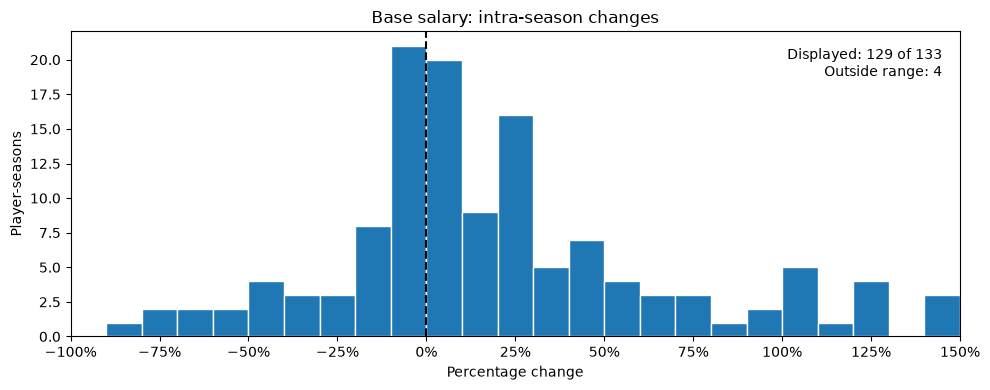

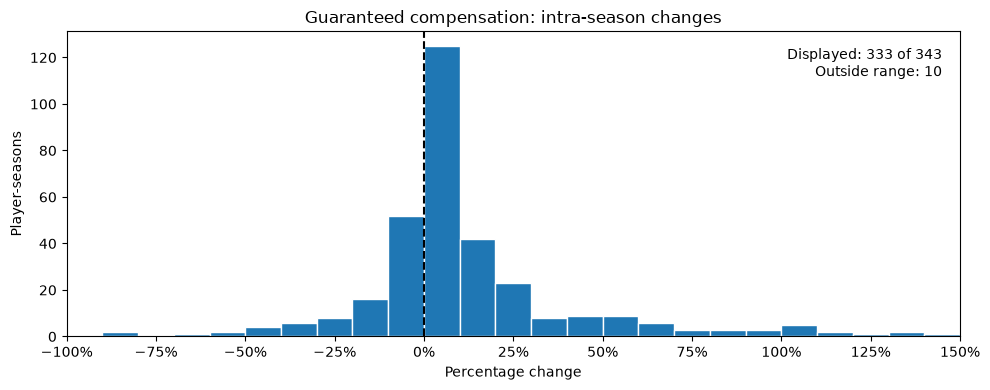

In [18]:
lower, upper = -100, 150
bins = np.arange(lower, upper + 10, 10)

for metric, label in [
    ("base", "Base salary"),
    ("gc", "Guaranteed compensation")
]:
    pct = changes.loc[
        changes[f"{metric}_change"].ne(0),
        f"{metric}_pct"
    ].dropna()

    visible = pct[pct.between(lower, upper)]
    outside = len(pct) - len(visible)

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.hist(visible, bins=bins, edgecolor="white")
    ax.axvline(0, linestyle="--", color="black")

    ax.set_xlim(lower, upper)
    ax.set_xticks(np.arange(lower, upper + 1, 25))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))

    ax.set_title(f"{label}: intra-season changes")
    ax.set_xlabel("Percentage change")
    ax.set_ylabel("Player-seasons")

    ax.text(
        0.98, 0.95,
        f"Displayed: {len(visible)} of {len(pct)}\n"
        f"Outside range: {outside}",
        transform=ax.transAxes,
        ha="right",
        va="top"
    )

    plt.tight_layout()
    plt.show()

In [16]:
for metric in ["base", "gc"]:
    display(
        changes.nlargest(5, f"{metric}_pct")[[
            "Player", "Season",
            "first_team", "last_team",
            f"{metric}_first",
            f"{metric}_last",
            f"{metric}_change",
            f"{metric}_pct"
        ]]
    )

,Player,Season,first_team,last_team,base_first,base_last,base_change,base_pct
1880,Duncan McGuire,2024,ORL,ORL,89716,825000,735284,819.568416
1978,Efrain Álvarez,2021,LAG,LAG,110004,500000,389996,354.528926
3482,Julian Araujo,2021,LAG,LAG,140000,550000,410000,292.857143
4587,Milan Iloski,2025,SD,PHI,156000,500000,344000,220.512821
125,Aidan Morris,2023,CLB,CLB,200000,500000,300000,150.000000


,Player,Season,first_team,last_team,gc_first,gc_last,gc_change,gc_pct
1880,Duncan McGuire,2024,ORL,ORL,99716,1146000,1046284,1049.263910
1978,Efrain Álvarez,2021,LAG,LAG,114738,612167,497429,433.534662
3482,Julian Araujo,2021,LAG,LAG,146250,653750,507500,347.008547
4587,Milan Iloski,2025,SD,PHI,156000,552569,396569,254.210897
480,Andrés Romero,2017,MTL,MTL,120000,405000,285000,237.500000


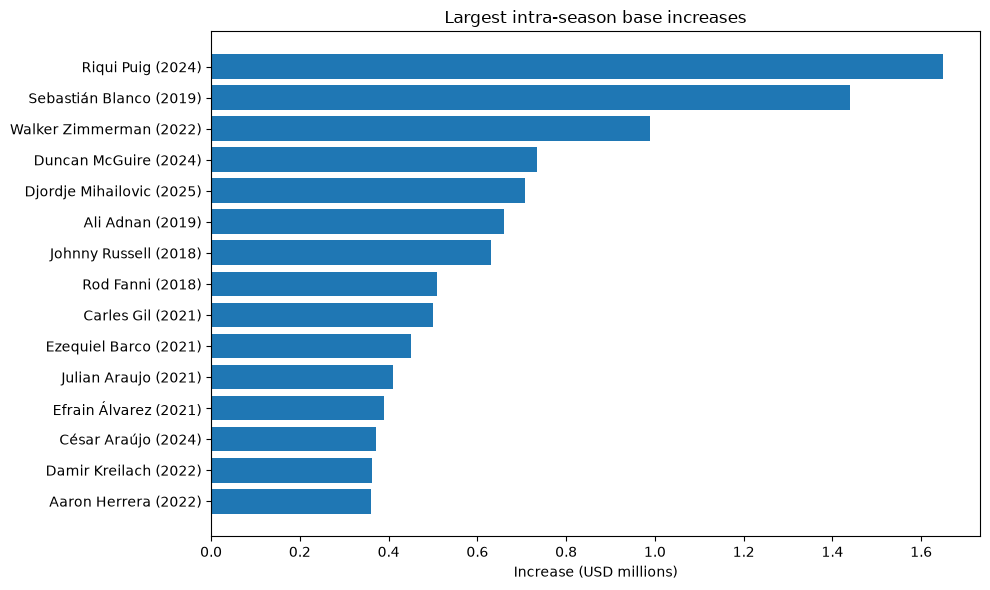

,Player,Season,first_team,last_team,base_first,base_last,base_change,base_pct
5226,Riqui Puig,2024,LAG,LAG,2349996,4000000,1650004,70.213056
5595,Sebastián Blanco,2019,POR,POR,1300008,2740008,1440000,110.768549
6145,Walker Zimmerman,2022,NSH,NSH,1100000,2088235,988235,89.839545
1880,Duncan McGuire,2024,ORL,ORL,89716,825000,735284,819.568416
1819,Djordje Mihailovic,2025,COL,TOR,1450000,2158335,708335,48.850690
298,Ali Adnan,2019,VAN,VAN,539000,1200000,661000,122.634508
3194,Johnny Russell,2018,SKC,SKC,700000,1331579,631579,90.225571
5268,Rod Fanni,2018,MTL,MTL,690000,1200000,510000,73.913043
1037,Carles Gil,2021,NER,NER,2250000,2750000,500000,22.222222
2180,Ezequiel Barco,2021,ATL,ATL,1425000,1875000,450000,31.578947


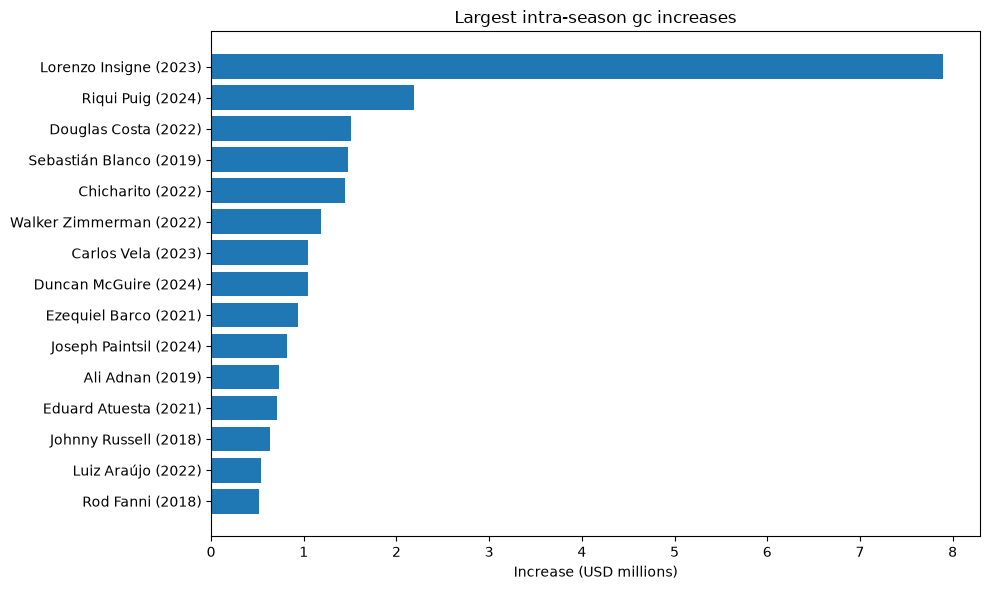

,Player,Season,first_team,last_team,gc_first,gc_last,gc_change,gc_pct
3982,Lorenzo Insigne,2023,TOR,TOR,7500000,15400000,7900000,105.333333
5226,Riqui Puig,2024,LAG,LAG,2449996,4642188,2192192,89.477371
1856,Douglas Costa,2022,LAG,LAG,3000000,4508333,1508333,50.277767
5595,Sebastián Blanco,2019,POR,POR,1375008,2853341,1478333,107.514502
1117,Chicharito,2022,LAG,LAG,6000000,7443750,1443750,24.062500
6145,Walker Zimmerman,2022,NSH,NSH,1156050,2345214,1189164,102.864409
1076,Carlos Vela,2023,LAFC,LAFC,3337500,4383900,1046400,31.352809
1880,Duncan McGuire,2024,ORL,ORL,99716,1146000,1046284,1049.263910
2180,Ezequiel Barco,2021,ATL,ATL,1425000,2358333,933333,65.497053
3353,Joseph Paintsil,2024,LAG,LAG,3358000,4182000,824000,24.538416


In [15]:
for metric in ["base", "gc"]:
    top = (
        changes[changes[f"{metric}_change"].gt(0)]
        .nlargest(15, f"{metric}_change")
        .copy()
    )

    top["label"] = (
        top["Player"] + " (" + top["Season"].astype(str) + ")"
    )

    top = top.sort_values(f"{metric}_change")

    plt.figure(figsize=(10, 6))
    plt.barh(
        top["label"],
        top[f"{metric}_change"] / 1_000_000
    )
    plt.xlabel("Increase (USD millions)")
    plt.title(f"Largest intra-season {metric} increases")
    plt.tight_layout()
    plt.show()

    display(
        top[[
            "Player", "Season",
            "first_team", "last_team",
            f"{metric}_first",
            f"{metric}_last",
            f"{metric}_change",
            f"{metric}_pct"
        ]].iloc[::-1]
    )

In [19]:
two_report_seasons = (
    report_schedule.groupby("Season")["Date"]
    .nunique()
)

two_report_seasons = two_report_seasons[
    two_report_seasons.eq(2)
].index

presence = salary_comparison[
    salary_comparison["Season"].isin(two_report_seasons)
].copy()

presence["report"] = np.where(
    presence["Date"].eq(
        presence.groupby("Season")["Date"].transform("min")
    ),
    "early",
    "late"
)

report_presence = (
    presence
    .groupby(["Player", "Season"])["report"]
    .agg(lambda x: "+".join(sorted(set(x))))
    .reset_index(name="presence")
)

report_presence["presence"] = report_presence["presence"].map({
    "early": "Early only",
    "late": "Late only",
    "early+late": "Both"
})

presence_summary = pd.crosstab(
    report_presence["Season"],
    report_presence["presence"]
).reindex(
    columns=["Early only", "Both", "Late only"],
    fill_value=0
)

display(presence_summary)

display(presence_summary.sum())

presence,Early only,Both,Late only
Season,,,
2016,25,523,57
2017,23,591,62
2018,29,632,52
2019,27,654,51
2021,26,755,100
2022,73,756,90
2023,42,827,88
2024,61,805,87
2025,57,833,97


presence
Early only     363
Both          6376
Late only      684
dtype: int64

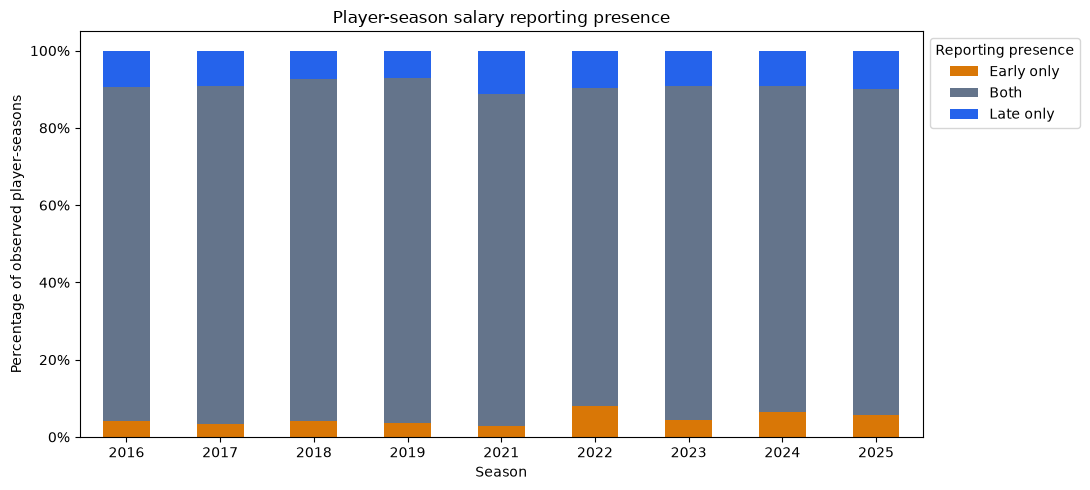

In [20]:
presence_pct = presence_summary.div(
    presence_summary.sum(axis=1),
    axis=0
).mul(100)

ax = presence_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5),
    color=["#D97706", "#64748B", "#2563EB"]
)

ax.set_title("Player-season salary reporting presence")
ax.set_xlabel("Season")
ax.set_ylabel("Percentage of observed player-seasons")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.legend(title="Reporting presence", loc="upper left",
          bbox_to_anchor=(1, 1))

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
keys = ["Player", "Season"]

ordered = salary_comparison.sort_values("Date")

first = ordered.groupby(keys).head(1)
last = ordered.groupby(keys).tail(1)

previous = last.copy()
previous["Season"] += 1

inter_season = previous.merge(
    first,
    on=keys,
    suffixes=("_previous", "_current"),
    validate="one_to_one"
)

for col in salary_cols:
    inter_season[f"{col} Change"] = (
        inter_season[f"{col}_current"]
        - inter_season[f"{col}_previous"]
    )

print(f"Consecutive season transitions: {len(inter_season):,}")

summary = {}

for col in salary_cols:
    delta = inter_season[f"{col} Change"]

    counts = pd.Series({
        "Increased": delta.gt(0).sum(),
        "Unchanged": delta.eq(0).sum(),
        "Decreased": delta.lt(0).sum()
    })

    summary[col] = pd.DataFrame({
        "Count": counts,
        "Percentage": (counts / len(delta) * 100).round(2)
    })

display(pd.concat(summary, axis=1))

Consecutive season transitions: 6,148


Base Salary            Guaranteed Compensation           
                Count Percentage                   Count Percentage
Increased        4971      80.86                    4948      80.48
Unchanged         618      10.05                     553       8.99
Decreased         559       9.09                     647      10.52

In [23]:
for col in salary_cols:
    previous = inter_season[f"{col}_previous"]

    inter_season[f"{col} Pct Change"] = (
        inter_season[f"{col} Change"]
        / previous.where(previous.gt(0))
        * 100
    )

    print(f"\n{col} — Percentage change")

    display(
        inter_season[f"{col} Pct Change"]
        .describe(percentiles=[.05, .25, .50, .75, .95])
        .round(2)
    )

    print("Most frequent percentage changes")

    display(
        inter_season[f"{col} Pct Change"]
        .round(1)
        .value_counts()
        .head(15)
        .rename("Transitions")
        .to_frame()
    )


Base Salary — Percentage change


count    6148.00
mean       26.01
std        69.87
min       -94.40
5%        -25.68
25%         4.55
50%        11.11
75%        28.57
95%       111.11
max      1780.18
Name: Base Salary Pct Change, dtype: float64

Most frequent percentage changes


,Transitions
Base Salary Pct Change,
0.0,627
5.0,407
10.0,163
25.0,111
20.0,110
12.5,101
11.1,86
16.7,84
9.2,76



Guaranteed Compensation — Percentage change


count    6148.00
mean       24.02
std        62.16
min       -95.27
5%        -26.12
25%         3.84
50%        10.05
75%        26.65
95%       105.44
max       994.02
Name: Guaranteed Compensation Pct Change, dtype: float64

Most frequent percentage changes


,Transitions
Guaranteed Compensation Pct Change,
0.0,565
5.0,281
10.0,57
9.0,47
6.0,41
12.9,40
4.8,39
30.4,35
9.2,35


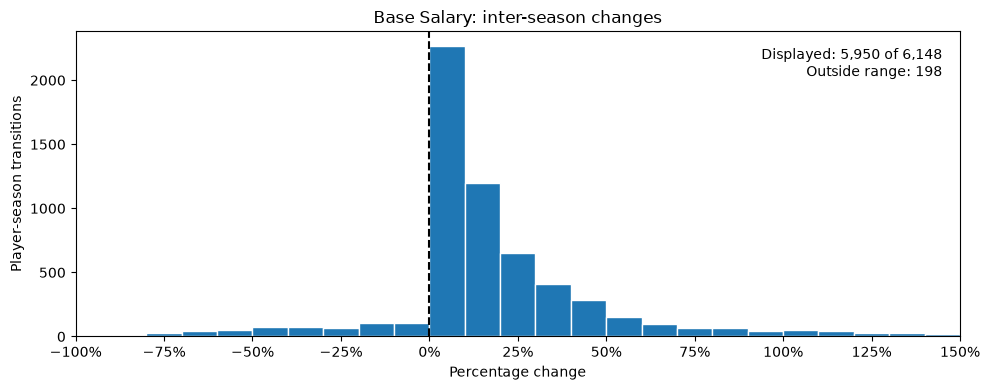

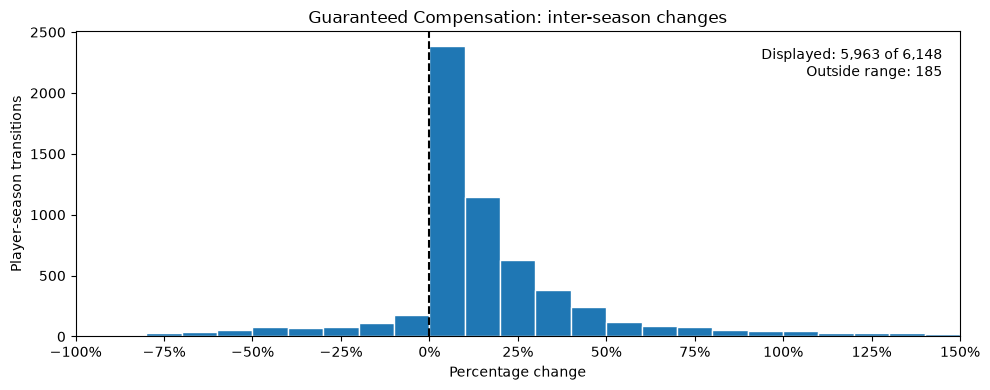

In [24]:
for col in salary_cols:
    pct = inter_season[f"{col} Pct Change"].dropna()
    visible = pct[pct.between(-100, 150)]

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.hist(
        visible,
        bins=np.arange(-100, 160, 10),
        edgecolor="white"
    )

    ax.axvline(0, linestyle="--", color="black")
    ax.set_xlim(-100, 150)
    ax.set_xticks(np.arange(-100, 151, 25))
    ax.xaxis.set_major_formatter(PercentFormatter(100))

    ax.set_title(f"{col}: inter-season changes")
    ax.set_xlabel("Percentage change")
    ax.set_ylabel("Player-season transitions")

    ax.text(
        0.98, 0.95,
        f"Displayed: {len(visible):,} of {len(pct):,}\n"
        f"Outside range: {len(pct) - len(visible):,}",
        transform=ax.transAxes,
        ha="right",
        va="top"
    )

    plt.tight_layout()
    plt.show()

In [25]:
five_pct = inter_season[
    inter_season["Base Salary Pct Change"].round(1).eq(5.0)
]

display(
    five_pct.groupby("Season")
    .size()
    .rename("Transitions with 5% increase")
    .to_frame()
)

display(
    five_pct.groupby([
        "Base Salary_previous",
        "Base Salary_current"
    ])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .rename("Transitions")
    .to_frame()
)

,Transitions with 5% increase
Season,
2017,59
2018,57
2019,63
2020,10
2021,54
2022,49
2023,49
2024,54
2025,6


,,Transitions
Base Salary_previous,Base Salary_current,
85444,89716,51
63547,66724,47
81375,85444,41
54500,57225,21
65500,68775,19
67500,70875,17
84000,88200,17
53004,55654,15
51500,54075,14
